In a liquid-phase reactor, A + B ⇌ C reaches equilibrium. Initial concentrations are [A]0 = 1.0 mol/L, [B]0 = 1.0 mol/L, and [C]0 = 0 mol/L. If x mol/L of C forms, then [A] = [B] = 1 - x and [C] = x, so Kc = x / (1 - x)^2. The quadratic equation is Kc*x^2 - (2*Kc + 1)*x + Kc = 0.

1. Read Kc using input(), print the data types of the raw input and converted value, and show a clear message if the text is not a number or if Kc <= 0.

2. Find a, b, c, the discriminant, and both roots.

3. Select the physically meaningful root (0 <= x <= 1).

4. Print the equilibrium concentrations [A], [B], and [C] to 3 decimal places and the limiting-reactant conversion x / 1.0 * 100%.

5. Classify the conversion using if/elif/else: >=70% is High, >=40% is Moderate, otherwise Low.

In [49]:
import math

raw_kc = input("Enter the equilibrium constant Kc: ")
print("K_c:", raw_kc)
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted value type:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Error: Kc must be a finite number greater than 0.")
    else:
        # Kc = x / (1 - x)^2  ->  Kc*x^2 - (2*Kc + 1)*x + Kc = 0
        a = kc
        b = -(2 * kc + 1)
        c = kc
        discriminant = b**2 - 4 * a * c

        print(f"a = {a}, b = {b}, c = {c}")
        print("Discriminant:", discriminant)

        if discriminant < 0:
            print("No real roots.")
        else:
            root_1 = (-b + math.sqrt(discriminant)) / (2 * a)
            root_2 = (-b - math.sqrt(discriminant)) / (2 * a)
            print("Root 1:", root_1)
            print("Root 2:", root_2)

            physical_roots = [root for root in (root_1, root_2) if 0 <= root <= 1]
            if not physical_roots:
                print("No physically meaningful root in the range 0 <= x <= 1.")
            else:
                x = physical_roots[0]
                concentration_a = 1.0 - x
                concentration_b = 1.0 - x
                concentration_c = x
                conversion = x / 1.0 * 100

                print(f"Selected physical root: x = {x:.3f} mol/L")
                print(f"Equilibrium [A] = {concentration_a:.3f} mol/L")
                print(f"Equilibrium [B] = {concentration_b:.3f} mol/L")
                print(f"Equilibrium [C] = {concentration_c:.3f} mol/L")
                print(f"Limiting-reactant conversion = {conversion:.3f}%")

                if conversion >= 70:
                    classification = "High"
                elif conversion >= 40:
                    classification = "Moderate"
                else:
                    classification = "Low"
                print("Conversion classification:", classification)

K_c: -2
Raw input type: <class 'str'>
Converted value type: <class 'float'>
Error: Kc must be a finite number greater than 0.


 Q2 PART A) A batch reactor decomposes reactant A (A-> products) by a first order reaction dC/dT=-kC. Use the Euler method: C_new = C_old-k*C_old △t. Take c=2mol/L k=0.08/min △t=1min 

 1)using a for loop simulate 10 minutes and print a table of time,concentration and conversion.

 2)using math.exp(), calculate the exact value Ce to power (-kt) at 10 min and print the absolute error of the euler result. 

 3)Using a while loop repeat the simulation until conversion reaches 60% or time reaches 100 min. Print the time needed and the final concentration. 

  

In [32]:
# Euler simulation for 10 minutes
C0 = 2.0       # Initial concentration (mol/L)
k_rate = 0.08   # First-order rate constant (min^-1)
dt = 1.0       # Time step (min)
time_min = 10

C_euler = C0
print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"0\t\t{C_euler:.4f}\t\t\t{0.0:.2f}")

for t in range(1, time_min + 1):
    C_euler = C_euler - k_rate * C_euler * dt
    conversion_pct = (C0 - C_euler) / C0 * 100
    print(f"{t}\t\t{C_euler:.4f}\t\t\t{conversion_pct:.2f}")

# Exact concentration and absolute error at 10 minutes
C_exact = C0 * math.exp(-k_rate * time_min)
absolute_error = abs(C_exact - C_euler)

print(f"\nExact concentration at {time_min} min: {C_exact:.4f} mol/L")
print(f"Absolute error: {absolute_error:.4f} mol/L")

# Euler simulation until conversion reaches 60% or time reaches 100 minutes
C_while = C0
time_while = 0

while (C0 - C_while) / C0 < 0.60 and time_while < 100:
    C_while = C_while - k_rate * C_while * dt
    time_while += dt

final_conversion = (C0 - C_while) / C0 * 100
print(f"\nTime needed: {time_while:g} min")
print(f"Final concentration: {C_while:.4f} mol/L")
print(f"Final conversion: {final_conversion:.2f}%")

Time (min)	Concentration (mol/L)	Conversion (%)
0		2.0000			0.00
1		1.8400			8.00
2		1.6928			15.36
3		1.5574			22.13
4		1.4328			28.36
5		1.3182			34.09
6		1.2127			39.36
7		1.1157			44.22
8		1.0264			48.68
9		0.9443			52.78
10		0.8688			56.56

Exact concentration at 10 min: 0.8987 mol/L
Absolute error: 0.0299 mol/L

Time needed: 11 min
Final concentration: 0.7993 mol/L
Final conversion: 60.04%


PartB) Batch lables such as PLANT20261030 are stored as text. Write a program that reads a lable, loops through each character and prints the number of digits and the sum of digits. Show a messege for an empty label and for a label with no digits. Test with PLANT20261030, an empty label and ABCDEF

In [50]:
label = input("Enter a batch label: ")
print("Analyzing batch label:", label)
if label == "":
    print("Error: Batch label cannot be empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in label:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    print("Number of digits:", digit_count)
    print("Sum of digits:", digit_sum)

    if digit_count == 0:
        print("No digits found in the label.")

Analyzing batch label: abcde
Number of digits: 0
Sum of digits: 0
No digits found in the label.


Q3 Part.A . A laboratory has n candidate additives and wants to test r of them together in one formulation (order does not matter). Write a recursive function  factorial(n) (remember the base case for 0!) and a function combination (n,r) = n! / (r! (n-r)!) that uses it. Reject invalid input (negative values,r>n).Print the number of possible formulations for n = 6,r=3, and show the message for n=5,r=7.

 


In [38]:
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise ValueError("n must be an integer.")
    if n < 0:
        raise ValueError("n must be non-negative.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or isinstance(n, bool):
        raise ValueError("n must be an integer.")
    if not isinstance(r, int) or isinstance(r, bool):
        raise ValueError("r must be an integer.")
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


def print_formulation_count(n, r):
    try:
        count = combination(n, r)
    except ValueError as error:
        print(f"Invalid input for n={n}, r={r}: {error}")
    else:
        print(f"Number of formulations for n={n}, r={r}: {count}")


print_formulation_count(6, 3)
print_formulation_count(5, 7)

Number of formulations for n=6, r=3: 20
Invalid input for n=5, r=7: r cannot be greater than n.


Part B. During a REACTION,samples are taken at times = Fibonacci number *4min. Write an itirative function fib_iter(n) that returns a list of first n Fibonacci numbers(Fo = 0 ,F1 = 1). For n = 10 , check that both functions agree and print  a table :Sample . | Fibonacci tag | Sampling time (min).


In [39]:
def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")
    sequence = []
    first, second = 0, 1
    for _ in range(n):
        sequence.append(first)
        first, second = second, first + second
    return sequence


def fib_rec(n):
    if n < 0:
        raise ValueError("n must be non-negative.")
    if n <= 1:
        return n
    return fib_rec(n - 1) + fib_rec(n - 2)


n = 10
fibonacci_tags = fib_iter(n)
recursive_tags = [fib_rec(i) for i in range(n)]

if fibonacci_tags == recursive_tags:
    print("Iterative and recursive Fibonacci results agree.")
else:
    print("The Fibonacci results do not agree.")

print("\nSample | Fibonacci tag | Sampling time (min)")
for sample, tag in enumerate(fibonacci_tags, start=1):
    print(f"{sample:6} | {tag:14} | {tag * 4:19}")

Iterative and recursive Fibonacci results agree.

Sample | Fibonacci tag | Sampling time (min)
     1 |              0 |                   0
     2 |              1 |                   4
     3 |              1 |                   4
     4 |              2 |                   8
     5 |              3 |                  12
     6 |              5 |                  20
     7 |              8 |                  32
     8 |             13 |                  52
     9 |             21 |                  84
    10 |             34 |                 136


Q4 Hydrolysis of an ester was studied at two temperature. The concentration (mol/L) was recorded:
Tme_min = 0,10,2,30,40,50
Run1_mol_L(LOW T) = 1,0.74,0.55,0.41,0.30,0.22
Run2_mol_(high T) = 1.00,0.61,0.37,0.22,0.14,0.08

a)Create a Dataframe from this table. Save it as kinetics.csv(without the index column) and as kinetics.json. Read and print its shape and data types.

b) Print the mean standard deviation of Run1 and Run2, and state which run shows more variation.

c) Plot both runs on one graph (Time on x-axis) with title,axis lable with units ,legend and grid.

d) Nitrogen gas is compressed slowly in a piston_cylinder at constant temperature

VOLUME_L=1,2,3,4,5
PRESSURE_BAR =4,2.03,1.31,1.02,0.81
PLOT a pressure vs. volume as a scatter plot. Calculate k as thr mean of P*V and draw a refrence curve p= k/v on the same graph. add title,labels with units and legends

Read-back shape: (6, 3)
Data types:
 Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Mean and standard deviation:
Run1_mol_L: mean=0.537, std=0.293
Run2_mol_L: mean=0.403, std=0.349
Run2 shows more variation.


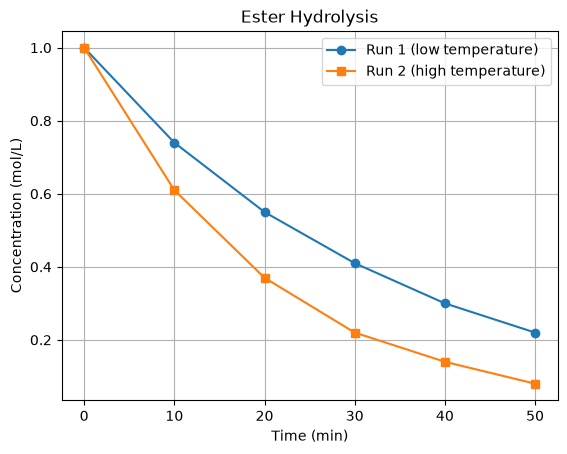

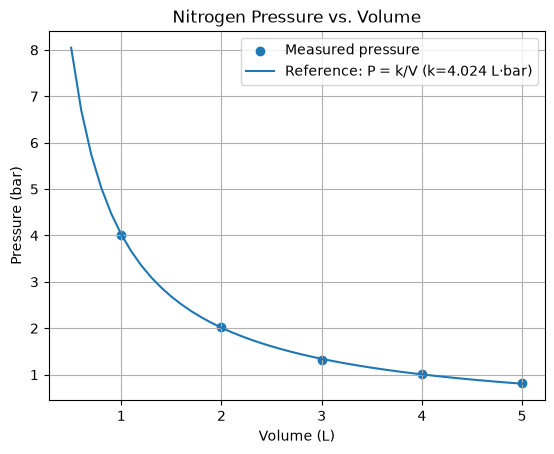

In [53]:
import pandas as pd
import matplotlib.pyplot as plt

# Ester hydrolysis data (the time point after 10 min is 20 min)
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_mol_L": [1.00, 0.61, 0.37, 0.22, 0.14, 0.08],
})

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_readback = pd.read_csv("kinetics.csv")
print("Read-back shape:", kinetics_readback.shape)
print("Data types:\n", kinetics_readback.dtypes)

print("\nMean and standard deviation:")
for run in ["Run1_mol_L", "Run2_mol_L"]:
    print(f"{run}: mean={kinetics_readback[run].mean():.3f}, "
          f"std={kinetics_readback[run].std():.3f}")

if kinetics_readback["Run1_mol_L"].std() > kinetics_readback["Run2_mol_L"].std():
    print("Run1 shows more variation.")
elif kinetics_readback["Run2_mol_L"].std() > kinetics_readback["Run1_mol_L"].std():
    print("Run2 shows more variation.")
else:
    print("Both runs show the same variation.")

plt.figure()
plt.plot(kinetics_readback["Time_min"], kinetics_readback["Run1_mol_L"],
         marker="o", label="Run 1 (low temperature)")
plt.plot(kinetics_readback["Time_min"], kinetics_readback["Run2_mol_L"],
         marker="s", label="Run 2 (high temperature)")
plt.title("Ester Hydrolysis")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

# Nitrogen gas pressure-volume data
volume_L = [1, 2, 3, 4, 5]
pressure_bar = [4.00, 2.03, 1.31, 1.02, 0.81]
pv_values = [volume * pressure for volume, pressure in zip(volume_L, pressure_bar)]
pv_mean_k = sum(pv_values) / len(pv_values)
reference_volume = [step / 10 for step in range(5, 51)]
reference_pressure = [pv_mean_k / volume for volume in reference_volume]

plt.figure()
plt.scatter(volume_L, pressure_bar, label="Measured pressure")
plt.plot(reference_volume, reference_pressure,
         label=f"Reference: P = k/V (k={pv_mean_k:.3f} L·bar)")
plt.title("Nitrogen Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.show()